In [3]:
!pip install kagglehub

In [4]:
import kagglehub

path = kagglehub.dataset_download(
    "ssssws/chocolate-sales-dataset-2023-2024"
)

print(path)

C:\Users\chiar\.cache\kagglehub\datasets\ssssws\chocolate-sales-dataset-2023-2024\versions\2


In [5]:
import os

print(os.listdir(path))

['calendar.csv', 'customers.csv', 'products.csv', 'sales.csv', 'stores.csv']


In [6]:
import pandas as pd
import os

print(path)

file_path = os.path.join(path, "sales.csv")

print(file_path)

sales = pd.read_csv(file_path)

sales.head()

C:\Users\chiar\.cache\kagglehub\datasets\ssssws\chocolate-sales-dataset-2023-2024\versions\2
C:\Users\chiar\.cache\kagglehub\datasets\ssssws\chocolate-sales-dataset-2023-2024\versions\2\sales.csv


,order_id,order_date,product_id,store_id,customer_id,quantity,unit_price,discount,revenue,cost,profit
0,0RD00000001,2023-01-07,P0080,S093,C040749,5,14.43,0.15,61.33,42.77,18.56
1,0RD00000002,2023-10-22,P0173,S065,C020161,3,12.01,0.00,36.03,19.06,16.97
2,0RD00000003,2023-05-07,P0115,S078,C048069,2,10.02,0.00,20.04,10.29,9.75
3,0RD00000004,2024-06-23,P0186,S088,C047901,2,14.66,0.10,26.39,16.35,10.04
4,0RD00000005,2024-09-24,P0197,S054,C033950,1,12.34,0.00,12.34,7.94,4.40


In [7]:
import os

print(os.listdir(path))

['calendar.csv', 'customers.csv', 'products.csv', 'sales.csv', 'stores.csv']


In [8]:
sales.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000000 entries, 0 to 999999
Data columns (total 11 columns):
 #   Column       Non-Null Count    Dtype  
---  ------       --------------    -----  
 0   order_id     1000000 non-null  object 
 1   order_date   1000000 non-null  object 
 2   product_id   1000000 non-null  object 
 3   store_id     1000000 non-null  object 
 4   customer_id  1000000 non-null  object 
 5   quantity     1000000 non-null  int64  
 6   unit_price   1000000 non-null  float64
 7   discount     1000000 non-null  float64
 8   revenue      1000000 non-null  float64
 9   cost         1000000 non-null  float64
 10  profit       1000000 non-null  float64
dtypes: float64(5), int64(1), object(5)
memory usage: 83.9+ MB


In [9]:
sales.describe()

,quantity,unit_price,discount,revenue,cost,profit
count,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000
mean,2.999589,9.002449,0.056248,25.486129,15.291554,10.194565
std,1.413621,3.462902,0.076809,16.367864,9.972706,6.778760
min,1.000000,3.000000,0.000000,2.400000,1.200000,0.730000
25%,2.000000,6.000000,0.000000,12.160000,7.240000,4.780000
50%,3.000000,9.010000,0.000000,21.920000,13.030000,8.600000
75%,4.000000,12.000000,0.150000,35.880000,21.410000,14.170000
max,5.000000,15.000000,0.200000,75.000000,52.430000,37.430000


In [10]:
sales.columns

Index(['order_id', 'order_date', 'product_id', 'store_id', 'customer_id',
       'quantity', 'unit_price', 'discount', 'revenue', 'cost', 'profit'],
      dtype='object')

In [11]:
#analisi delle colonne categoriche di sales
for column in sales.columns:
    if sales[column].dtype == "object":
        print( f"{column} contains categorical data.")
        unique_values = sales[column].nunique()
        print(f"{column} contains {unique_values} unique values.")
        print(f"distribution for every unique value is as such:")
        all_counts = sales[column].value_counts()
        print(all_counts)
        print()

order_id contains categorical data.
order_id contains 1000000 unique values.
distribution for every unique value is as such:
order_id
0RD00000001    1
0RD00666658    1
0RD00666660    1
0RD00666661    1
0RD00666662    1
              ..
0RD00333338    1
0RD00333339    1
0RD00333340    1
0RD00333341    1
0RD01000000    1
Name: count, Length: 1000000, dtype: int64

order_date contains categorical data.
order_date contains 731 unique values.
distribution for every unique value is as such:
order_date
2023-06-10    1463
2024-08-29    1458
2024-09-01    1458
2024-03-02    1455
2024-07-01    1447
              ... 
2023-04-23    1259
2024-09-30    1255
2024-06-26    1253
2023-02-20    1252
2024-08-17    1241
Name: count, Length: 731, dtype: int64

product_id contains categorical data.
product_id contains 202 unique values.
distribution for every unique value is as such:
product_id
P0021    5141
P0091    5132
P0107    5115
P0008    5092
P0146    5089
         ... 
P0080    4808
P0178    4797
P0

In [12]:
# individuazione dei dati nulli in sales
for column in sales.columns:
    nan_count = sales[column].isna().sum()
    nan_percent= round(nan_count/sales.shape[0]*100, 2)
    print( f"{column} contains {nan_count} NaN values, {nan_percent}% of total values.")

order_id contains 0 NaN values, 0.0% of total values.
order_date contains 0 NaN values, 0.0% of total values.
product_id contains 0 NaN values, 0.0% of total values.
store_id contains 0 NaN values, 0.0% of total values.
customer_id contains 0 NaN values, 0.0% of total values.
quantity contains 0 NaN values, 0.0% of total values.
unit_price contains 0 NaN values, 0.0% of total values.
discount contains 0 NaN values, 0.0% of total values.
revenue contains 0 NaN values, 0.0% of total values.
cost contains 0 NaN values, 0.0% of total values.
profit contains 0 NaN values, 0.0% of total values.


In [13]:
products = pd.read_csv(os.path.join(path, "products.csv"))

customers = pd.read_csv(os.path.join(path, "customers.csv"))

calendar = pd.read_csv(os.path.join(path, "calendar.csv"))

stores = pd.read_csv(os.path.join(path, "stores.csv"))

In [14]:
print(products.head())
#analisi delle colonne numeriche di products

print(products.describe())
print(products.info())

  product_id           product_name    brand category  cocoa_percent  weight_g
0      P0001    White Chocolate 80%     Mars  Truffle             80       120
1      P0002     Dark Chocolate 70%  Cadbury  Praline             70       100
2      P0003  Truffle Chocolate 70%  Hershey  Praline             70       120
3      P0004     Milk Chocolate 50%     Mars  Praline             50        80
4      P0005    White Chocolate 70%  Ferrero    White             70        50
       cocoa_percent    weight_g
count     200.000000  200.000000
mean       69.150000  107.500000
std        14.623499   50.898954
min        50.000000   50.000000
25%        50.000000   80.000000
50%        70.000000  100.000000
75%        80.000000  120.000000
max        90.000000  200.000000
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   product_id     200 non-null    obj

In [15]:
#analisi delle colonne categoriche di products
print(products.columns)
for column in products.columns:
    if products[column].dtype== "object":
        print(f"{column} column contains categorical data.")
        unique_count = products[column].nunique()
        print(f"{column} contains {unique_count} unique values")
        all_counts = products[column].value_counts()
        print(f"Distribution of every unique value is as such:")
        print(all_counts)
        print()

Index(['product_id', 'product_name', 'brand', 'category', 'cocoa_percent',
       'weight_g'],
      dtype='object')
product_id column contains categorical data.
product_id contains 200 unique values
Distribution of every unique value is as such:
product_id
P0001    1
P0138    1
P0128    1
P0129    1
P0130    1
        ..
P0070    1
P0071    1
P0072    1
P0073    1
P0200    1
Name: count, Length: 200, dtype: int64

product_name column contains categorical data.
product_name contains 25 unique values
Distribution of every unique value is as such:
product_name
Dark Chocolate 50%       14
Truffle Chocolate 80%    13
Praline Chocolate 50%    11
Milk Chocolate 70%       11
White Chocolate 50%      10
Dark Chocolate 60%       10
Truffle Chocolate 90%     9
White Chocolate 80%       9
White Chocolate 90%       9
Praline Chocolate 70%     9
Truffle Chocolate 50%     8
Dark Chocolate 70%        8
Dark Chocolate 90%        8
White Chocolate 70%       8
Milk Chocolate 50%        8
Milk Chocolate 

In [16]:
# individuazione dei valori nulli in products
for column in products.columns:
    nan_count = products[column].isna().sum()
    nan_percent = round(nan_count/products.shape[0]*100, 2)
    print(f"{column} contains {nan_count} NaN values, which is {nan_percent}% of total values.")

product_id contains 0 NaN values, which is 0.0% of total values.
product_name contains 0 NaN values, which is 0.0% of total values.
brand contains 0 NaN values, which is 0.0% of total values.
category contains 0 NaN values, which is 0.0% of total values.
cocoa_percent contains 0 NaN values, which is 0.0% of total values.
weight_g contains 0 NaN values, which is 0.0% of total values.


In [17]:
print(customers.head())
#analisi delle colonne numeriche di customers
print(
    customers.info()
)
print(
    customers.describe()
)

  customer_id  age  gender  loyalty_member   join_date
0     C000001   40    Male               1  2025-05-21
1     C000002   47    Male               0  2021-12-26
2     C000003   58  Female               1  2022-09-13
3     C000004   25  Female               0  2025-02-27
4     C000005   43    Male               0  2023-08-31
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   customer_id     50000 non-null  object
 1   age             50000 non-null  int64 
 2   gender          50000 non-null  object
 3   loyalty_member  50000 non-null  int64 
 4   join_date       50000 non-null  object
dtypes: int64(2), object(3)
memory usage: 1.9+ MB
None
                age  loyalty_member
count  50000.000000    50000.000000
mean      44.026100        0.502080
std       15.328333        0.500001
min       18.000000        0.000000
25%       31.000000

In [18]:
#analisi delle colonne categoriche di customers
for column in customers.columns:
    if customers[column].dtype== "object":
        print(f"{column} contains categorical data. ")
        unique_obj = customers[column].nunique()
        print(f"{column} contains {unique_obj} unique objects.")
        all_counts = customers[column].value_counts()
        print(f"distribution for every unique value is as such:")
        print(all_counts)
        print()

customer_id contains categorical data. 
customer_id contains 50000 unique objects.
distribution for every unique value is as such:
customer_id
C000001    1
C033351    1
C033329    1
C033330    1
C033331    1
          ..
C016669    1
C016670    1
C016671    1
C016672    1
C050000    1
Name: count, Length: 50000, dtype: int64

gender contains categorical data. 
gender contains 2 unique objects.
distribution for every unique value is as such:
gender
Male      25242
Female    24758
Name: count, dtype: int64

join_date contains categorical data. 
join_date contains 1827 unique objects.
distribution for every unique value is as such:
join_date
2023-09-06    46
2025-11-03    45
2025-11-23    44
2023-03-05    43
2025-01-05    43
              ..
2021-03-26    14
2026-01-18    14
2026-01-03    13
2022-02-23    13
2023-05-02    12
Name: count, Length: 1827, dtype: int64



In [19]:
#individuazione dei valori nulli in customers
for column in customers.columns:
    nan_count = customers[column].isna().sum()
    nan_percent = round(nan_count/customers.shape[0]*100, 2)
    print(f"{column} contains {nan_count} NaN values, which is {nan_percent}% of total values.")

customer_id contains 0 NaN values, which is 0.0% of total values.
age contains 0 NaN values, which is 0.0% of total values.
gender contains 0 NaN values, which is 0.0% of total values.
loyalty_member contains 0 NaN values, which is 0.0% of total values.
join_date contains 0 NaN values, which is 0.0% of total values.


In [20]:
# analisi delle colonne numeriche di stores
print(
    stores.head()
)
print(
    stores.columns
)
print(
    stores.info()
)
print(
    stores.describe()
)

  store_id         store_name       city country store_type
0     S001  Chocolate Store 1   New York  Canada     Retail
1     S002  Chocolate Store 2  Melbourne  Canada       Mall
2     S003  Chocolate Store 3     Berlin  France       Mall
3     S004  Chocolate Store 4      Paris      UK    Airport
4     S005  Chocolate Store 5     Sydney     USA     Online
Index(['store_id', 'store_name', 'city', 'country', 'store_type'], dtype='object')
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   store_id    100 non-null    object
 1   store_name  100 non-null    object
 2   city        100 non-null    object
 3   country     100 non-null    object
 4   store_type  100 non-null    object
dtypes: object(5)
memory usage: 4.0+ KB
None
       store_id         store_name     city country store_type
count       100                100      100     100        100
uni

In [21]:
# analisi delle colonne categoriche
for column in stores.columns:
    if stores[column].dtype == "object":
        print (f"{column} column contains categorial data.")
        unique_values = stores[column].nunique()
        print( f"{column} contains {unique_values} unique values.")
        all_values = stores[column].value_counts()
        print(f"distribution for every unique value is as such:")
        print(all_values)
        print()

store_id column contains categorial data.
store_id contains 100 unique values.
distribution for every unique value is as such:
store_id
S001    1
S064    1
S074    1
S073    1
S072    1
       ..
S031    1
S030    1
S029    1
S028    1
S100    1
Name: count, Length: 100, dtype: int64

store_name column contains categorial data.
store_name contains 100 unique values.
distribution for every unique value is as such:
store_name
Chocolate Store 1      1
Chocolate Store 64     1
Chocolate Store 74     1
Chocolate Store 73     1
Chocolate Store 72     1
                      ..
Chocolate Store 31     1
Chocolate Store 30     1
Chocolate Store 29     1
Chocolate Store 28     1
Chocolate Store 100    1
Name: count, Length: 100, dtype: int64

city column contains categorial data.
city contains 7 unique values.
distribution for every unique value is as such:
city
Toronto      18
Paris        16
London       16
New York     15
Sydney       13
Melbourne    12
Berlin       10
Name: count, dtype: int

In [22]:
#individuazione dei valori nulli in stores
for column in stores.columns:
    nan_count = stores[column].isna().sum()
    nan_percent = round(nan_count/stores.shape[0]*100, 2)
    print( f"{column} contains {nan_count} NaN values, which is {nan_percent}% of total values.")

store_id contains 0 NaN values, which is 0.0% of total values.
store_name contains 0 NaN values, which is 0.0% of total values.
city contains 0 NaN values, which is 0.0% of total values.
country contains 0 NaN values, which is 0.0% of total values.
store_type contains 0 NaN values, which is 0.0% of total values.


In [23]:
sales['quantity'].sum() #vendite totali dell'azienda

2999589

In [24]:
# Quali sono i prodotti più venduti? TOP 5
sales_products = sales.merge(products, on= "product_id")
most_sold_prod = sales_products.groupby('product_name')['quantity'].sum().sort_values(ascending=False).head(5)
print(most_sold_prod)

product_name
Dark Chocolate 50%       208996
Truffle Chocolate 80%    193431
Praline Chocolate 50%    162670
Milk Chocolate 70%       162335
Dark Chocolate 60%       149346
Name: quantity, dtype: int64


<Axes: xlabel='brand', ylabel='count'>

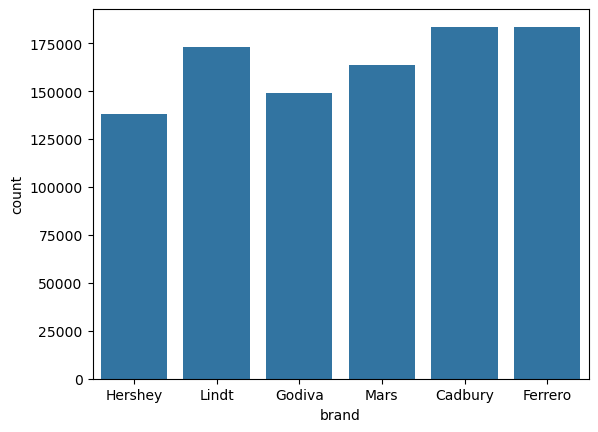

In [65]:
import seaborn as sns
sns.countplot(data=sales_products, x='brand')

In [64]:
# I prodotti che hanno portato più guadagno, TOP 5
sales_products.groupby('product_name')['profit'].sum().sort_values(ascending=False).head(5)

product_name
Dark Chocolate 50%       709742.67
Truffle Chocolate 80%    656761.72
Milk Chocolate 70%       553576.55
Praline Chocolate 50%    553128.09
Dark Chocolate 60%       508956.58
Name: profit, dtype: float64

In [26]:
sales_customers = sales.merge(customers, on= 'customer_id')
sales_stores= sales.merge(stores, on ='store_id')

In [27]:
# i prodotti che sono costati di più. TOP 5
sales_products.groupby('product_name')['cost'].sum().sort_values(ascending=False).head(5)

product_name
Dark Chocolate 50%       1065297.93
Truffle Chocolate 80%     986496.29
Milk Chocolate 70%        831180.72
Praline Chocolate 50%     829468.36
Dark Chocolate 60%        763692.97
Name: cost, dtype: float64

In [28]:
# Quanto hanno comprato le varie fasce di età

In [29]:
sales_customers_products = sales_customers.merge(products, on = 'product_id')

In [30]:
sales_customers_products["ageGroup"] = pd.cut(
    sales_customers_products["age"],
    bins=[0, 25, 35, 50, 100],
    labels=["18-25", "26-35", "36-50", "50+"])

In [31]:
sales_customers_products.columns

Index(['order_id', 'order_date', 'product_id', 'store_id', 'customer_id',
       'quantity', 'unit_price', 'discount', 'revenue', 'cost', 'profit',
       'age', 'gender', 'loyalty_member', 'join_date', 'product_name', 'brand',
       'category', 'cocoa_percent', 'weight_g', 'ageGroup'],
      dtype='object')

In [32]:
sales_customers_products.groupby(
    'ageGroup',
    observed=False
)['quantity'].sum().sort_values(ascending=False).head(5)

ageGroup
50+      1123816
36-50     842207
26-35     551459
18-25     452988
Name: quantity, dtype: int64

<Axes: xlabel='ageGroup', ylabel='count'>

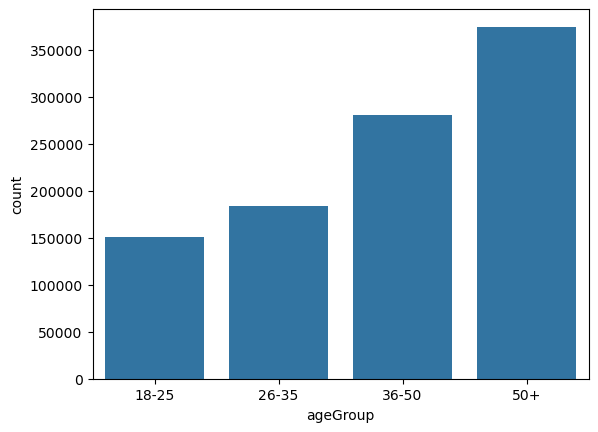

In [70]:
sns.countplot(data= sales_customers_products, x= 'ageGroup')

In [33]:
# TOP 5 PRODOTTI PER FASCIA DI ETA'
Top_5_per_agegroup = sales_customers_products.groupby(
    ['ageGroup', 'product_name'],
    observed=False
)['quantity'].sum().reset_index().sort_values(['ageGroup', 'quantity'], ascending=[True, False]).groupby('ageGroup', observed=False).head(5)

print(Top_5_per_agegroup)

   ageGroup           product_name  quantity
0     18-25     Dark Chocolate 50%     31921
18    18-25  Truffle Chocolate 80%     29028
10    18-25  Praline Chocolate 50%     24699
7     18-25     Milk Chocolate 70%     24639
1     18-25     Dark Chocolate 60%     22889
25    26-35     Dark Chocolate 50%     38936
43    26-35  Truffle Chocolate 80%     35867
35    26-35  Praline Chocolate 50%     30002
32    26-35     Milk Chocolate 70%     29817
26    26-35     Dark Chocolate 60%     28253
50    36-50     Dark Chocolate 50%     59301
68    36-50  Truffle Chocolate 80%     54983
60    36-50  Praline Chocolate 50%     46165
57    36-50     Milk Chocolate 70%     45762
70    36-50    White Chocolate 50%     42097
75      50+     Dark Chocolate 50%     78838
93      50+  Truffle Chocolate 80%     73553
82      50+     Milk Chocolate 70%     62117
85      50+  Praline Chocolate 50%     61804
95      50+    White Chocolate 50%     56643


In [73]:
pivot = sales_customers_products.pivot_table(index= 'ageGroup', columns='brand', values= 'quantity', observed= False)

<Axes: xlabel='brand', ylabel='ageGroup'>

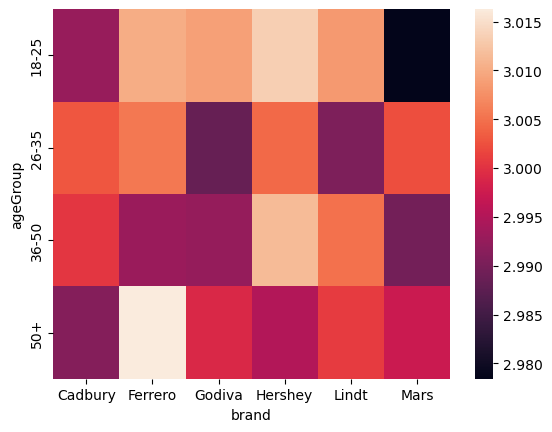

In [74]:
sns.heatmap(pivot)

In [34]:
# prodotti preferiti dai 50+
top_10_agegroup_50plus = sales_customers_products.groupby(
    ['ageGroup', 'product_name'],
    observed=False
)['quantity'].sum().reset_index().query("ageGroup == '50+'").sort_values('quantity', ascending=False).head(10)

print(top_10_agegroup_50plus)

   ageGroup           product_name  quantity
75      50+     Dark Chocolate 50%     78838
93      50+  Truffle Chocolate 80%     73553
82      50+     Milk Chocolate 70%     62117
85      50+  Praline Chocolate 50%     61804
95      50+    White Chocolate 50%     56643
76      50+     Dark Chocolate 60%     56429
99      50+    White Chocolate 90%     50634
98      50+    White Chocolate 80%     50468
87      50+  Praline Chocolate 70%     50172
94      50+  Truffle Chocolate 90%     50044


In [35]:
# prodotti preferiti dai giovani
top_10_agegroup_18_35 = sales_customers_products.groupby(['ageGroup', 'product_name'], observed=False)['quantity'].sum().reset_index().query("ageGroup == '18-25' or ageGroup == '26-35'").sort_values('quantity',ascending=False).head(10)

print(top_10_agegroup_18_35)

   ageGroup           product_name  quantity
25    26-35     Dark Chocolate 50%     38936
43    26-35  Truffle Chocolate 80%     35867
0     18-25     Dark Chocolate 50%     31921
35    26-35  Praline Chocolate 50%     30002
32    26-35     Milk Chocolate 70%     29817
18    18-25  Truffle Chocolate 80%     29028
26    26-35     Dark Chocolate 60%     28253
45    26-35    White Chocolate 50%     27936
44    26-35  Truffle Chocolate 90%     25157
49    26-35    White Chocolate 90%     24914


In [36]:
# PERCENTUALE DI LOYALTY MEMBERSHIP per fascia di età
sales_customers_products.groupby('ageGroup', observed=False)['loyalty_member'].mean().sort_values(ascending=False)

ageGroup
50+      0.503385
18-25    0.502405
26-35    0.501599
36-50    0.499687
Name: loyalty_member, dtype: float64

In [37]:
# TOP 5 STORE con piu guadagni
sales_stores.groupby(['store_name', 'city'])['profit'].sum().sort_values(ascending= False).head(5)

store_name          city    
Chocolate Store 74  Sydney      104809.57
Chocolate Store 33  Toronto     104519.64
Chocolate Store 50  New York    104000.38
Chocolate Store 27  Sydney      103834.60
Chocolate Store 22  Berlin      103699.15
Name: profit, dtype: float64

In [46]:
sales_customers_products_stores = sales_customers_products.merge(stores, on = 'store_id')

In [47]:
sales_customers_products_stores.columns

Index(['order_id', 'order_date', 'product_id', 'store_id', 'customer_id',
       'quantity', 'unit_price', 'discount', 'revenue', 'cost', 'profit',
       'age', 'gender', 'loyalty_member', 'join_date', 'product_name', 'brand',
       'category', 'cocoa_percent', 'weight_g', 'ageGroup', 'store_name',
       'city', 'country', 'store_type'],
      dtype='object')

In [48]:
#TOP 5 stores per age group
top_5_stores_per_age = sales_customers_products_stores.groupby(['ageGroup','store_name', 'city'], observed = False)['quantity'].sum().reset_index().sort_values(['ageGroup', 'quantity'], ascending=[True,False]).groupby('ageGroup', observed=False).head(5)

print(top_5_stores_per_age)

     ageGroup          store_name       city  quantity
580     18-25  Chocolate Store 83    Toronto      4810
427     18-25  Chocolate Store 64     Berlin      4800
620     18-25  Chocolate Store 89      Paris      4790
325     18-25  Chocolate Store 50   New York      4780
689     18-25  Chocolate Store 98   New York      4770
703     26-35   Chocolate Store 1   New York      5900
1088    26-35  Chocolate Store 59   New York      5824
1209    26-35  Chocolate Store 74     Sydney      5782
1290    26-35  Chocolate Store 85  Melbourne      5754
1066    26-35  Chocolate Store 56  Melbourne      5739
1505    36-50  Chocolate Store 22     Berlin      8839
1725    36-50  Chocolate Store 50   New York      8808
1798    36-50   Chocolate Store 6    Toronto      8753
2042    36-50  Chocolate Store 91     Sydney      8742
1429    36-50  Chocolate Store 12     London      8728
2245      50+  Chocolate Store 27     Sydney     11620
2609      50+  Chocolate Store 74     Sydney     11617
2159      

In [80]:
top_5_stores_per_age = (sales_customers_products_stores.groupby(['ageGroup','store_name', 'city'], observed = False)['quantity'].sum().reset_index())
pivot= top_5_stores_per_age.pivot_table(index= 'ageGroup', columns='city', values= 'quantity', observed=False)
pivot

city,Berlin,London,Melbourne,New York,Paris,Sydney,Toronto
ageGroup,,,,,,,
18-25,454.95,718.80,546.24,682.33,724.16,588.76,814.64
26-35,551.20,875.00,663.92,835.98,869.14,722.68,996.67
36-50,846.68,1346.25,1006.60,1270.42,1340.41,1099.29,1512.42
50+,1129.35,1793.01,1341.99,1689.76,1797.61,1459.32,2027.12


<Axes: xlabel='city', ylabel='ageGroup'>

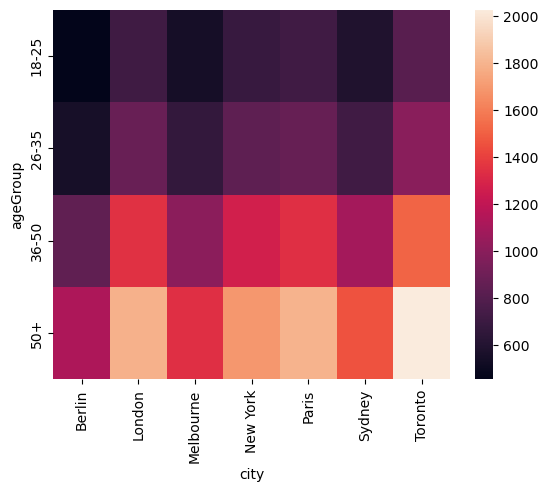

In [81]:
sns.heatmap(pivot)

In [49]:
# stores with the most loyalty memebers
top_stores_loyalty_memebers= sales_customers_products_stores.groupby(['store_name', 'city'])['loyalty_member'].sum().sort_values(ascending=False).head(10)

print(top_stores_loyalty_memebers)

store_name          city     
Chocolate Store 33  Toronto      5139
Chocolate Store 27  Sydney       5113
Chocolate Store 74  Sydney       5107
Chocolate Store 94  Paris        5070
Chocolate Store 72  New York     5068
Chocolate Store 6   Toronto      5066
Chocolate Store 16  New York     5062
Chocolate Store 17  Melbourne    5062
Chocolate Store 31  Paris        5054
Chocolate Store 80  Sydney       5051
Name: loyalty_member, dtype: int64


In [50]:
# queries temporali: anno con più venite, mesi con più vendite, 
#prodotti più venduti negli anni, marche che hanno fatturato di più negli anni, 
#fatturato delle nazioni per anno
calendar.columns

Index(['date', 'year', 'month', 'day', 'week', 'day_of_week'], dtype='object')

In [51]:
calendar['date'] = pd.to_datetime(calendar['date'])
sales['order_date'] = pd.to_datetime(sales['order_date'])
sales_calendar = sales.merge(calendar, left_on = 'order_date', right_on = 'date')

In [52]:
yearly_sales = sales_calendar.groupby('year', observed=False)['quantity'].sum().sort_index()
print(yearly_sales)

year
2023    1498104
2024    1501485
Name: quantity, dtype: int64


<Axes: xlabel='year', ylabel='quantity'>

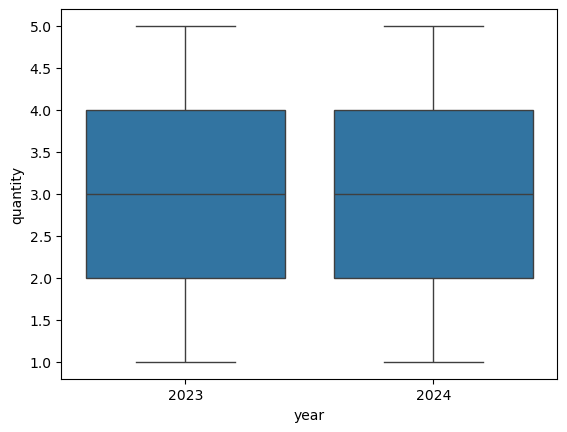

In [53]:
import seaborn as sns
sns.boxplot(data=sales_calendar, x= 'year', y= 'quantity')

In [54]:
yearly_increment = yearly_sales.diff()
print(yearly_increment)

year
2023       NaN
2024    3381.0
Name: quantity, dtype: float64


In [55]:
yearly_increment_pct = yearly_sales.pct_change()*100
print(yearly_increment_pct)

year
2023         NaN
2024    0.225685
Name: quantity, dtype: float64


In [56]:
yearly_summary = pd.DataFrame({'total_quantity': yearly_sales, 'incremento_annuale': yearly_increment, 'percentuale_incremento': yearly_increment_pct})
print(yearly_summary)

      total_quantity  incremento_annuale  percentuale_incremento
year                                                            
2023         1498104                 NaN                     NaN
2024         1501485              3381.0                0.225685


In [57]:
# vendite totali per mese nel 2024
monthly_sales_2024 = sales_calendar.groupby(['year','month'], observed=False)['quantity'].sum().reset_index().query("year == 2024")

monthly_profit_2024 = sales_calendar.groupby(['year', 'month'], observed=False)['profit'].sum().reset_index().query("year == 2024")

monthly_2024 = monthly_sales_2024.merge(monthly_profit_2024, on= ['year','month'])
print(monthly_2024)

    year  month  quantity     profit
0   2024      1    127676  433505.26
1   2024      2    119074  403832.70
2   2024      3    127605  434068.29
3   2024      4    122805  417541.94
4   2024      5    126987  431456.80
5   2024      6    122183  415998.20
6   2024      7    127768  434268.21
7   2024      8    127646  433282.13
8   2024      9    123630  420756.85
9   2024     10    126677  430246.18
10  2024     11    122351  415617.27
11  2024     12    127083  430393.92


<Axes: xlabel='month', ylabel='year'>

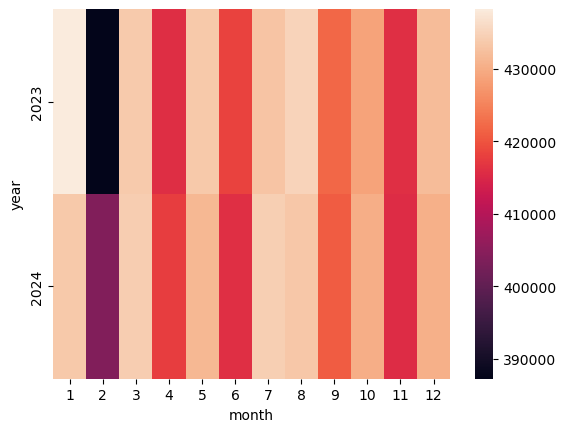

In [58]:
monthly_sales = (sales_calendar.groupby(['year','month'], observed=False)['profit'].sum().reset_index())
import seaborn as sns
monthly_sales_pivot = monthly_sales.pivot_table(index = 'year', columns='month', values ='profit')
sns.heatmap(monthly_sales_pivot)

In [59]:
# I mesi con più profitto
best_months = sales_calendar.groupby('month', observed=False)['profit'].sum().sort_values(ascending= False).head(3)
print(best_months)

month
1    871736.03
8    868271.37
3    867833.38
Name: profit, dtype: float64


In [60]:
sales_calendar_products= sales_calendar.merge(products, on = 'product_id')

In [61]:
# TOP 5 PRODOTTI che hanno venduto di più per anno
top_5_produ_per_year= sales_calendar_products.groupby(['year', 'product_name'], observed= False)['quantity'].sum().reset_index().sort_values(['year', 'quantity'], ascending= [True, False]).groupby('year').head()
print(top_5_produ_per_year)

    year           product_name  quantity
0   2023     Dark Chocolate 50%    104474
18  2023  Truffle Chocolate 80%     96724
7   2023     Milk Chocolate 70%     80985
10  2023  Praline Chocolate 50%     80720
20  2023    White Chocolate 50%     75050
25  2024     Dark Chocolate 50%    104522
43  2024  Truffle Chocolate 80%     96707
35  2024  Praline Chocolate 50%     81950
32  2024     Milk Chocolate 70%     81350
26  2024     Dark Chocolate 60%     75076


In [62]:
# TOP 5 BRAND che hanno creato più profitto per anno
top_5_brand_per_year= sales_calendar_products.groupby(['year', 'brand'], observed= False)['profit'].sum().reset_index().sort_values(['year', 'profit'], ascending= [True, False]).groupby('year').head()
print(top_5_brand_per_year)

    year    brand     profit
1   2023  Ferrero  934407.78
0   2023  Cadbury  931343.58
4   2023    Lindt  880015.82
5   2023     Mars  836974.83
2   2023   Godiva  758858.87
7   2024  Ferrero  941860.31
6   2024  Cadbury  934212.17
10  2024    Lindt  890168.72
11  2024     Mars  823853.97
8   2024   Godiva  756090.21


In [63]:
# vendite & fatturato delle nazioni per anno
sales_calendar_stores = sales_calendar.merge(stores, on = 'store_id')

country_sales = sales_calendar_stores.groupby(['year', 'country'], observed=False)['quantity'].sum().reset_index().sort_values(['year', 'quantity'], ascending = [True, False])

country_profit = sales_calendar_stores.groupby(['year', 'country'], observed=False)['profit'].sum().reset_index().sort_values(['year', 'profit'], ascending= [True, False])

country_per_year = country_sales.merge(country_profit, on = ['year', 'country'])

print(country_per_year)

    year    country  quantity      profit
0   2023     Canada    299602  1018160.47
1   2023         UK    283755   966311.33
2   2023        USA    254939   868108.23
3   2023     France    254604   863761.73
4   2023  Australia    224980   763913.42
5   2023    Germany    180224   613341.70
6   2024     Canada    299668  1015261.40
7   2024         UK    283992   963885.24
8   2024     France    255431   872052.56
9   2024        USA    255290   868701.35
10  2024  Australia    226911   770437.02
11  2024    Germany    180193   610630.18
